# Saber 11 - prediccion de alto desempeno
ML Zoomcamp 2026 - midterm project - Laura

objetivo: predecir si un estudiante va a tener alto desempeno en Saber 11 usando solo informacion del colegio, el hogar y el estudiante (nada de puntajes por area)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score, mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

## 1. Datos
muestra generada con `python download_data.py --periodo 20224`

In [2]:
df = pd.read_csv('data/saber11_sample.csv', dtype=str)
df.shape

(50000, 51)

In [3]:
df.head()

,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,TI,SB11202240445282,URBANO,N,A,TÉCNICO/ACADÉMICO,154001002462,154001002462,54,...,No,No,Si,A2,59,55,55,53,64,285
1,20224,CC,SB11202240588399,URBANO,N,A,ACADÉMICO,105604000013,105604000013,05,...,No,Si,Si,A-,33,33,38,35,45,187
2,20224,TI,SB11202240397480,URBANO,N,A,TÉCNICO/ACADÉMICO,305001025592,305001025592,05,...,Si,Si,Si,A-,38,59,53,60,60,282
3,20224,CC,SB11202240098186,RURAL,N,A,TÉCNICO/ACADÉMICO,252227000189,252227000189,52,...,No,Si,No,A-,34,29,34,39,38,175
4,20224,TI,SB11202240106185,URBANO,N,A,TÉCNICO/ACADÉMICO,105266000941,105266000941,05,...,Si,Si,Si,A2,61,53,45,50,61,265


In [4]:
df.columns.tolist()

['periodo',
 'estu_tipodocumento',
 'estu_consecutivo',
 'cole_area_ubicacion',
 'cole_bilingue',
 'cole_calendario',
 'cole_caracter',
 'cole_cod_dane_establecimiento',
 'cole_cod_dane_sede',
 'cole_cod_depto_ubicacion',
 'cole_cod_mcpio_ubicacion',
 'cole_codigo_icfes',
 'cole_depto_ubicacion',
 'cole_genero',
 'cole_jornada',
 'cole_mcpio_ubicacion',
 'cole_naturaleza',
 'cole_nombre_establecimiento',
 'cole_nombre_sede',
 'cole_sede_principal',
 'estu_cod_depto_presentacion',
 'estu_cod_mcpio_presentacion',
 'estu_cod_reside_depto',
 'estu_cod_reside_mcpio',
 'estu_depto_presentacion',
 'estu_depto_reside',
 'estu_estadoinvestigacion',
 'estu_estudiante',
 'estu_fechanacimiento',
 'estu_genero',
 'estu_mcpio_presentacion',
 'estu_mcpio_reside',
 'estu_nacionalidad',
 'estu_pais_reside',
 'estu_privado_libertad',
 'fami_cuartoshogar',
 'fami_educacionmadre',
 'fami_educacionpadre',
 'fami_estratovivienda',
 'fami_personashogar',
 'fami_tieneautomovil',
 'fami_tienecomputador',
 'fam

## 2. Limpieza

In [5]:
# duplicados
print('duplicados:', df.duplicated().sum())
df = df.drop_duplicates()

duplicados: 0


In [6]:
# porcentaje de nulos por columna
df.isnull().mean().sort_values(ascending=False).head(20).round(3)

cole_bilingue           0.177
fami_estratovivienda    0.067
fami_tieneinternet      0.060
fami_educacionmadre     0.059
fami_educacionpadre     0.059
fami_tieneautomovil     0.046
fami_tienelavadora      0.044
fami_tienecomputador    0.044
fami_cuartoshogar       0.044
fami_personashogar      0.043
cole_caracter           0.037
desemp_ingles           0.003
punt_ingles             0.003
estu_fechanacimiento    0.000
estu_genero             0.000
estu_consecutivo        0.000
estu_tipodocumento      0.000
cole_area_ubicacion     0.000
periodo                 0.000
cole_nombre_sede        0.000
dtype: float64

variables candidatas: solo informacion que existe antes del examen (colegio, hogar, estudiante).

no uso:
- `punt_*` (los puntajes por area forman el puntaje global -> fuga de datos)
- identificadores, codigos DANE, fechas, municipios (demasiadas categorias)

In [7]:
candidatas = [
    'cole_naturaleza', 'cole_area_ubicacion', 'cole_jornada', 'cole_bilingue',
    'cole_caracter', 'cole_genero', 'cole_calendario', 'cole_depto_ubicacion',
    'estu_genero',
    'fami_estratovivienda', 'fami_educacionmadre', 'fami_educacionpadre',
    'fami_tieneinternet', 'fami_tienecomputador', 'fami_tieneautomovil',
    'fami_tienelavadora', 'fami_personashogar', 'fami_cuartoshogar',
]

features = [c for c in candidatas if c in df.columns]
print('no estan en el dataset:', [c for c in candidatas if c not in df.columns])
print(len(features), 'variables')

no estan en el dataset: []
18 variables


los nulos en las preguntas del hogar no son aleatorios (el estudiante no respondio), asi que los dejo como su propia categoria 'NA'

In [8]:
df[features] = df[features].fillna('NA')

df['punt_global'] = pd.to_numeric(df['punt_global'], errors='coerce')
df = df[df['punt_global'].notna()]
df.shape

(50000, 51)

## 3. EDA
### puntaje global

In [9]:
df['punt_global'].describe()

count    50000.000000
mean       250.201880
std         51.888815
min         14.000000
25%        210.000000
50%        247.000000
75%        287.000000
max        472.000000
Name: punt_global, dtype: float64

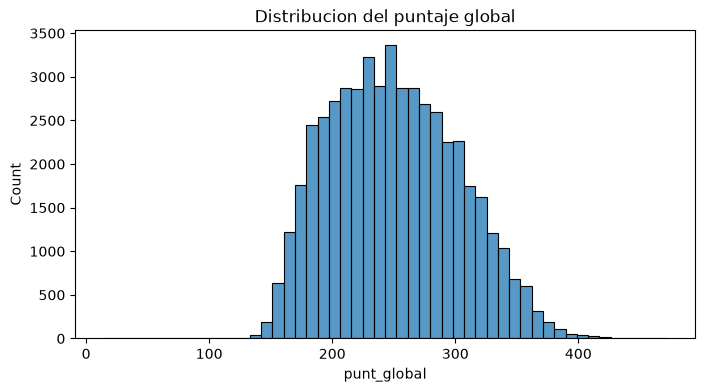

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(df['punt_global'], bins=50)
plt.title('Distribucion del puntaje global')
plt.show()

### variable objetivo
alto desempeno = estar en el 25% superior (percentil 75)

In [11]:
umbral = df['punt_global'].quantile(0.75)
df['alto_desempeno'] = (df['punt_global'] >= umbral).astype(int)

print('umbral:', umbral)
print('tasa de alto desempeno:', round(df['alto_desempeno'].mean(), 3))

umbral: 287.0
tasa de alto desempeno: 0.256


### alto desempeno por categoria

In [12]:
def tasa_por(col):
    return (df.groupby(col)['alto_desempeno']
              .agg(['mean', 'count'])
              .sort_values('mean', ascending=False)
              .round(3))

tasa_por('fami_estratovivienda') if 'fami_estratovivienda' in df.columns else None

,mean,count
fami_estratovivienda,,
Estrato 4,0.420,2578
Estrato 5,0.372,750
Estrato 3,0.342,10392
Estrato 6,0.338,355
Estrato 2,0.269,16923
Estrato 1,0.184,13790
NA,0.167,3327
Sin Estrato,0.067,1885


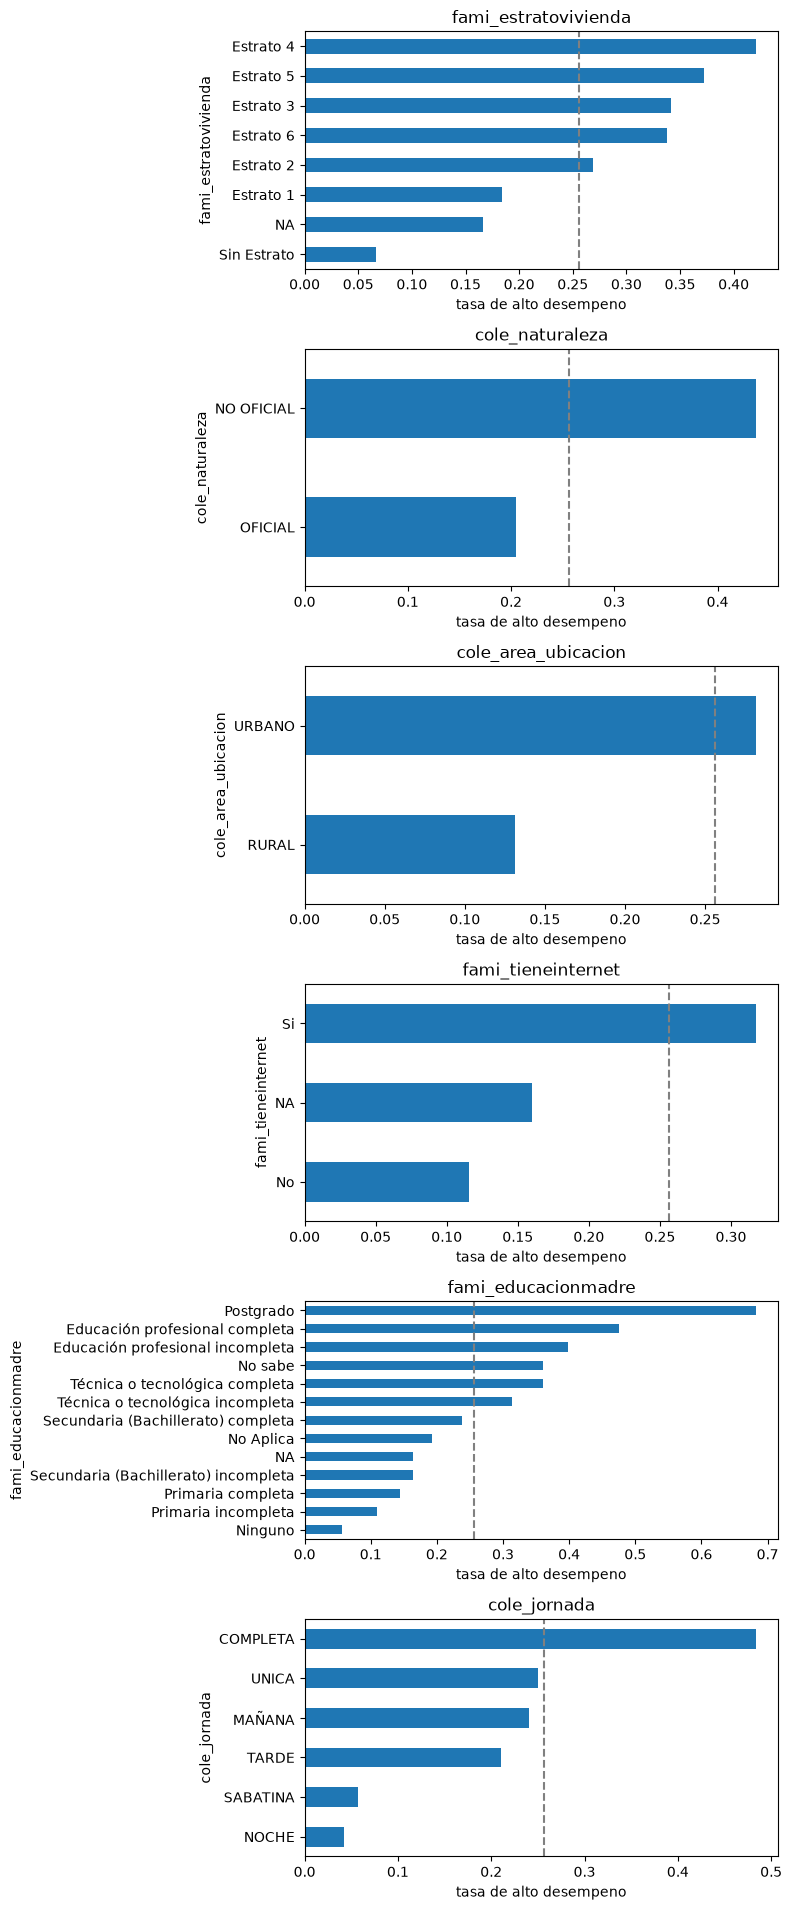

In [13]:
graficar = [c for c in ['fami_estratovivienda', 'cole_naturaleza', 'cole_area_ubicacion',
                        'fami_tieneinternet', 'fami_educacionmadre', 'cole_jornada'] if c in features]

fig, axes = plt.subplots(len(graficar), 1, figsize=(8, 3.2 * len(graficar)))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, graficar):
    t = df.groupby(col)['alto_desempeno'].mean().sort_values()
    t.plot.barh(ax=ax)
    ax.axvline(df['alto_desempeno'].mean(), color='gray', linestyle='--')
    ax.set_title(col)
    ax.set_xlabel('tasa de alto desempeno')
plt.tight_layout()
plt.show()

**conclusiones del EDA:**

- el puntaje global tiene una distribucion casi normal (promedio 250, mediana 247), con una cola leve hacia puntajes altos. el umbral de alto desempeno (percentil 75) quedo en 287 puntos
- el tipo de colegio marca mucha diferencia: en colegios no oficiales el 44% tiene alto desempeno, en los oficiales solo el 20%. pasa algo parecido con la zona: urbano 28% vs rural 13%
- la jornada es de las variables mas fuertes: la jornada completa llega al 48%, mientras que sabatina y nocturna estan cerca del 5% (probablemente son programas para adultos o validacion)
- la educacion de la madre tiene un efecto escalonado muy claro: de 6% cuando no tiene educacion hasta 68% cuando tiene postgrado
- tener internet en casa sube la tasa de 12% a 32%
- el estrato no es perfectamente ordenado: el estrato 4 tiene la tasa mas alta (42%) y el 6 queda por debajo del 4 y el 5. "sin estrato" es el grupo mas bajo (7%)
- los estudiantes que no respondieron (NA) quedan por debajo del promedio en todas las variables. por eso dejar el NA como categoria propia tiene sentido: no responder tambien es informacion

## 4. Importancia de variables
informacion mutua con el target (como en la tarea 3)

In [14]:
mi = pd.Series({c: mutual_info_score(df['alto_desempeno'], df[c]) for c in features})
mi = mi.sort_values(ascending=False)
mi.round(4)

fami_educacionmadre     0.0446
fami_educacionpadre     0.0380
cole_jornada            0.0321
fami_tienecomputador    0.0309
fami_tieneinternet      0.0237
cole_naturaleza         0.0228
fami_estratovivienda    0.0180
cole_depto_ubicacion    0.0177
fami_tieneautomovil     0.0148
cole_area_ubicacion     0.0093
fami_tienelavadora      0.0082
cole_genero             0.0064
fami_personashogar      0.0057
fami_cuartoshogar       0.0026
cole_caracter           0.0023
estu_genero             0.0020
cole_bilingue           0.0009
cole_calendario         0.0002
dtype: float64

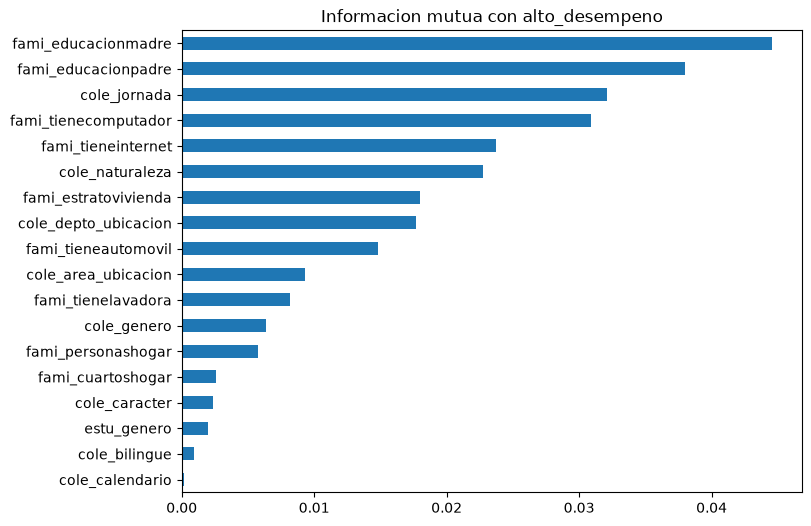

In [15]:
mi.sort_values().plot.barh(figsize=(8, 6))
plt.title('Informacion mutua con alto_desempeno')
plt.show()

**importancia de variables:**

- las variables del hogar son las que mas informacion aportan: educacion de la madre y del padre, tener computador e internet
- del colegio, las mas importantes son la jornada y la naturaleza (oficial / no oficial)
- el estrato aparece en la mitad: su efecto se reparte con otras variables relacionadas (internet, computador, automovil)
- genero del estudiante, colegio bilingue y calendario casi no aportan informacion

## 5. Split train / val / test
60 / 20 / 20

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train['alto_desempeno'].values
y_val = df_val['alto_desempeno'].values
y_test = df_test['alto_desempeno'].values

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

print(len(df_train), len(df_val), len(df_test))
X_train.shape

30000 10000 10000


(30000, 118)

In [17]:
resultados = []  # aqui guardo (modelo, parametros, auc)

## 6. Modelos
### 6.1 Regresion logistica (+ ajuste de C)

In [18]:
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000, solver='lbfgs')
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    resultados.append(('logistica', {'C': C}, auc))
    print(f'C={C:<6} auc={auc:.4f}')

C=0.01   auc=0.7762
C=0.1    auc=0.7777
C=1      auc=0.7772
C=10     auc=0.7769


### 6.2 Random forest (+ max_depth, min_samples_leaf)

In [19]:
for d in [10, 15, 20]:
    for leaf in [1, 5, 10]:
        m = RandomForestClassifier(n_estimators=100, max_depth=d, min_samples_leaf=leaf,
                                   random_state=1, n_jobs=-1)
        m.fit(X_train, y_train)
        auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
        resultados.append(('random_forest', {'max_depth': d, 'min_samples_leaf': leaf}, auc))
        print(f'max_depth={d:<3} min_samples_leaf={leaf:<3} auc={auc:.4f}')

max_depth=10  min_samples_leaf=1   auc=0.7641
max_depth=10  min_samples_leaf=5   auc=0.7639
max_depth=10  min_samples_leaf=10  auc=0.7631
max_depth=15  min_samples_leaf=1   auc=0.7685
max_depth=15  min_samples_leaf=5   auc=0.7699
max_depth=15  min_samples_leaf=10  auc=0.7692
max_depth=20  min_samples_leaf=1   auc=0.7652
max_depth=20  min_samples_leaf=5   auc=0.7707
max_depth=20  min_samples_leaf=10  auc=0.7712


### 6.3 XGBoost (+ learning_rate, max_depth)

In [20]:
for eta in [0.05, 0.1, 0.3]:
    for d in [3, 4, 6]:
        m = xgb.XGBClassifier(n_estimators=200, learning_rate=eta, max_depth=d,
                              random_state=1, n_jobs=-1)
        m.fit(X_train, y_train)
        auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
        resultados.append(('xgboost', {'learning_rate': eta, 'max_depth': d}, auc))
        print(f'learning_rate={eta:<5} max_depth={d}  auc={auc:.4f}')

learning_rate=0.05  max_depth=3  auc=0.7739
learning_rate=0.05  max_depth=4  auc=0.7766
learning_rate=0.05  max_depth=6  auc=0.7772
learning_rate=0.1   max_depth=3  auc=0.7786
learning_rate=0.1   max_depth=4  auc=0.7804
learning_rate=0.1   max_depth=6  auc=0.7775
learning_rate=0.3   max_depth=3  auc=0.7808
learning_rate=0.3   max_depth=4  auc=0.7777
learning_rate=0.3   max_depth=6  auc=0.7655


## 7. Comparacion y modelo final

In [21]:
df_res = pd.DataFrame(resultados, columns=['modelo', 'parametros', 'auc_val'])
mejores = df_res.loc[df_res.groupby('modelo')['auc_val'].idxmax()].sort_values('auc_val', ascending=False)
mejores

,modelo,parametros,auc_val
19,xgboost,"{'learning_rate': 0.3, 'max_depth': 3}",0.780793
1,logistica,{'C': 0.1},0.777663
12,random_forest,"{'max_depth': 20, 'min_samples_leaf': 10}",0.771178


**seleccion del modelo:**

- el mejor modelo en validacion es xgboost (learning_rate=0.3, max_depth=3) con AUC 0.781
- la regresion logistica (C=0.1) queda muy cerca con 0.778, y el random forest un poco mas abajo con 0.771
- la diferencia entre los tres es pequena (menos de 0.01), lo que indica que la relacion entre las variables y el resultado es bastante simple: la mayor parte de la senal la capturan las variables del hogar y del colegio vistas en el EDA
- elijo xgboost porque tiene la mejor AUC. la regresion logistica seria una buena alternativa si se necesitara un modelo mas facil de interpretar
- un AUC cercano a 0.78 tiene sentido: con informacion socioeconomica y del colegio se puede anticipar buena parte del resultado, pero no todo, porque el desempeno individual depende de otros factores que no estan en los datos

entreno el mejor con train + val y lo evaluo en test (datos que nunca vio)

In [22]:
ganador = mejores.iloc[0]
print('modelo:', ganador['modelo'], ganador['parametros'])

def crear_modelo(nombre, params):
    if nombre == 'logistica':
        return LogisticRegression(max_iter=1000, solver='lbfgs', **params)
    if nombre == 'random_forest':
        return RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1, **params)
    return xgb.XGBClassifier(n_estimators=200, random_state=1, n_jobs=-1, **params)

dv_final = DictVectorizer(sparse=True)
X_full = dv_final.fit_transform(df_full_train[features].to_dict(orient='records'))
X_test = dv_final.transform(df_test[features].to_dict(orient='records'))

modelo_final = crear_modelo(ganador['modelo'], ganador['parametros'])
modelo_final.fit(X_full, df_full_train['alto_desempeno'].values)

auc_test = roc_auc_score(y_test, modelo_final.predict_proba(X_test)[:, 1])
print('AUC validacion:', round(ganador['auc_val'], 4))
print('AUC test:      ', round(auc_test, 4))

modelo: xgboost {'learning_rate': 0.3, 'max_depth': 3}
AUC validacion: 0.7808
AUC test:       0.7767


### para copiar en `train.py`

In [23]:
print('MODELO =', repr(ganador['modelo']))
print('PARAMS =', ganador['parametros'])
print('FEATURES =', features)

MODELO = 'xgboost'
PARAMS = {'learning_rate': 0.3, 'max_depth': 3}
FEATURES = ['cole_naturaleza', 'cole_area_ubicacion', 'cole_jornada', 'cole_bilingue', 'cole_caracter', 'cole_genero', 'cole_calendario', 'cole_depto_ubicacion', 'estu_genero', 'fami_estratovivienda', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_tieneinternet', 'fami_tienecomputador', 'fami_tieneautomovil', 'fami_tienelavadora', 'fami_personashogar', 'fami_cuartoshogar']
